# IND320 project 2026
Philip A. K. Øvland \
Github:     https://github.com/Povland/IND320 \
Streamlit:  https://ind320-2026.streamlit.app/\

Video explaining stuff (Please tell me if the link doesn't work):
TO DO

## AI Usage

I used AI as a helping hand with:
    - planning
    - bug fixing
    - first version of code blocks
    - making sure I had the correct setup locally
    - giving suggestions to the log, this part, readme and structure.

Getting AI to help with logging (not doing it blindly), helped me remember all the problems I came across.


## Log - Tasks

Firstly we made the entire API-getting etc. into a package. It's the proper python way. We added src\ind320. In the pyproject.toml we now have:

[build-system]
requires = ["hatchling"]
build-backend = "hatchling.build"

[tool.hatch.build.targets.wheel]
packages = ["src/ind320"]

### Accounts and repositories
Reuse - done.
Peer review is officially done.

### Local database: Cassandra
Getting Cassandra up was the first wall. Docker Desktop wasn't running, and when it was, WSL crashed on start and had to be fixed first. Then Spark wouldn't start: uv had picked Python 3.14, which PySpark 3.5.1 doesn't support, so I pinned the project to 3.11. On Windows Spark also needs Java 17 and winutils (HADOOP_HOME). After that the Oslo/Ås test went through.

### Areas in the NVE API
NVE's area list (`HentOmråder`) has ten areas: Norway (NO 0), the five price areas (EL 1–5) and four watercourse areas (VASS 1–4).
But when I looked at the data, VASS 4 (Nord-Norge) was missing. To make sure it wasn't something in my own code, I checked the raw response from all three data endpoints:

```python
for endpoint in ["HentOffentligData", "HentOffentligDataSisteUke", "HentOffentligDataMinMaxMedian"]:
    raw = pd.DataFrame(nve.fetch_json(endpoint))
    vass = raw[raw["omrType"] == "VASS"]
    print(f"{endpoint}: VASS areas = {sorted(vass['omrnr'].unique())}, rows = {len(vass)}")
```

```
HentOffentligData: VASS areas = [1, 2, 3], rows = 4974
HentOffentligDataSisteUke: VASS areas = [1, 2, 3], rows = 3
HentOffentligDataMinMaxMedian: VASS areas = [1, 2, 3], rows = 159
```

None of them have VASS 4. The numbers add up (3 areas × 1658 weeks, 3 × 1 week, 3 × 53 weeks), so VASS 4 only exists in the area list.
Also, the Swagger docs say `HentOmråder` returns an object, but it returns a list with one object inside, so I had to check the actual response instead of trusting the docs.

### ENTSO-E
Getting api access was a bit of a headache. I sent a email to the wrong email, which I found out a few days layer. So on friday morning I still hadn't gotten the API key. At 16:14 on friday I got a email saying I got access. Then I had to get the key, which at first showed my a error. ![ENTSO-E unexpected error](screenshot_entsoe_unexpected_error.png)
Fetching two years for all 9 connections took 25 minutes, so the result is saved as a local backup and loaded from there afterwards.

Another large problem: Storing the data in Cassandra lost 4 rows per connection, and only the row counts revealed it. The cause was time zones in three places: pandas, PySpark (Python) and the Cassandra connector (Java) each convert times through the PC’s local time. The hour that happens twice when the clocks go back to winter time collapsed into one row. The fix was to send the time to Spark as a plain number (seconds since 1970) and to set Java’s time zone to UTC.

This was solved after I got my AI claude on the case. 

### Streamlit
The app now gets its data from NVE's API instead of the CSV. The API has no date parameters, so everything is downloaded once (cached) and the slider picks the period. Pages two and three got radio buttons for EL/NO/VASS and a dropdown for which areas to show. The choices follow you between pages, which took a few tries, since Streamlit forgets widget state when you switch page. The new cross border page reads straight from MongoDB, with the month pills stacked in a list.

Written: 16.10.2026

# Setup
Imports used throughout the notebook. Data access lives in the `ind320` package (`src/ind320/`), installed with `uv sync`.

In [15]:
import os
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from ind320 import nve

print("Python:", sys.version.split()[0])
print("Running from:", Path.cwd())

Python: 3.11.17
Running from: c:\Users\povla\Desktop\gitto\IND320\notebooks


# Local database: Cassandra
Cassandra runs locally in Docker:

```
docker run --name my_cassandra -p 9042:9042 -d cassandra:latest   # first time
docker start my_cassandra                                          # afterwards
```

Cassandra needs 30 to 90 seconds to start. The keyspace `ind320_v1` uses `SimpleStrategy` with replication factor 1, since there is only one local node.

In [ ]:
from cassandra.cluster import Cluster

KEYSPACE = "ind320_v1"

cluster = Cluster(["localhost"], port=9042)
session = cluster.connect()

session.execute(f"""
    CREATE KEYSPACE IF NOT EXISTS {KEYSPACE}
    WITH replication = {{'class': 'SimpleStrategy', 'replication_factor': 1}}
""")
session.set_keyspace(KEYSPACE)

session.execute("CREATE TABLE IF NOT EXISTS test (id int PRIMARY KEY, name text)")

print("Cassandra version:", session.execute("SELECT release_version FROM system.local").one().release_version)
print("Keyspaces:", [row.keyspace_name for row in session.execute("SELECT keyspace_name FROM system_schema.keyspaces")])

Cassandra version: 5.0.9
Keyspaces: ['system_auth', 'system_schema', 'system_distributed', 'system', 'system_traces', 'ind320_v1']


# Spark
Spark 3.5.1 (PySpark) with the DataStax Spark Cassandra Connector. Requirements on Windows:
- Java 17 (`java -version`)
- Python 3.11 (PySpark 3.5.1 does not support 3.14, which `uv` picked at first)
- `PYSPARK_PYTHON` set to the same Python as the notebook

In [4]:
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("IND320")
    .config("spark.jars.packages", "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1")
    .config("spark.cassandra.connection.host", "localhost")
    .config("spark.cassandra.connection.port", "9042")
    .getOrCreate()
)
spark

## Test the Spark-Cassandra connection
Write a small DataFrame to Cassandra through Spark, then read it back.

In [5]:
test_df = spark.createDataFrame([(1, "Oslo"), (2, "Ås")], ["id", "name"])

test_df.write.format("org.apache.spark.sql.cassandra") \
    .options(keyspace=KEYSPACE, table="test") \
    .mode("append") \
    .save()

spark.read.format("org.apache.spark.sql.cassandra") \
    .options(keyspace=KEYSPACE, table="test") \
    .load() \
    .show()

+---+----+
| id|name|
+---+----+
|  1|Oslo|
|  2|  Ås|
+---+----+



# Remote database: MongoDB
MongoDB. Credentials are stored in `No_sync/atlas-credentials.env`, which is listed in `.gitignore`, with the variables `MONGODB_USERNAME`, `MONGODB_PASSWORD` and `MONGODB_URI`.

In [6]:
from pymongo import MongoClient


def load_env(path):
    #Reads KEY=value lines from a .env file (handles quotes and a Windows BOM).
    values = {}
    for line in Path(path).read_text(encoding="utf-8-sig").splitlines():
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        sep = "=" if "=" in line else ":"
        key, _, value = line.partition(sep)
        values[key.strip()] = value.strip().strip('"').strip("'")
    return values


creds = load_env("../No_sync/atlas-credentials.env")
print(list(creds.keys()))   # names only, never the values

mongo_client = MongoClient(creds["MONGODB_URI"], serverSelectionTimeoutMS=10000)
mongo_client.admin.command("ping")
print("Connected to MongoDB")

mongo_db = mongo_client["ind320"]

['MONGODB_USERNAME', 'MONGODB_PASSWORD', 'MONGODB_URI']
Connected to MongoDB


## Test that data can be manipulated from Python
Create, read, update and delete on a temporary collection.

In [7]:
test = mongo_db["test"]

test.insert_many([{"city": "Oslo", "area": "NO1"}, {"city": "Bergen", "area": "NO5"}])
print("After insert:", list(test.find({}, {"_id": 0})))

test.update_one({"city": "Bergen"}, {"$set": {"area": "NO5 (west)"}})
print("After update:", list(test.find({}, {"_id": 0})))

test.delete_one({"city": "Oslo"})
print("After delete:", list(test.find({}, {"_id": 0})))

test.drop()

After insert: [{'city': 'Oslo', 'area': 'NO1'}, {'city': 'Bergen', 'area': 'NO5'}]
After update: [{'city': 'Oslo', 'area': 'NO1'}, {'city': 'Bergen', 'area': 'NO5 (west)'}]
After delete: [{'city': 'Bergen', 'area': 'NO5 (west)'}]


# API: NVE Magasinstatistikk
- API: https://biapi.nve.no/magasinstatistikk/swagger/index.html
- Description: https://www.nve.no/energi/analyser-og-statistikk/magasinstatistikk/

The CSV from part 1 is replaced by a direct API connection (`ind320.nve`). 
I kept `data/reservoirs.csv` so that `Oblig1.ipynb` still runs.

In [8]:
# Fetches the data from NVE's API. Renaming headers, datetime conversion,
# index and sorting are done in nve.fetch_reservoir_data()
reservoirs = nve.fetch_reservoir_data()

# Printing data
reservoirs

,area_type,area_nr,iso_aar,iso_week,filling_degree,capacity_TWh,filling_TWh,next_publishing_date,filling_degree_last_week,filling_degree_change
date_id,,,,,,,,,,
1995-01-08,EL,5,1995,1,0.616448,17.390587,10.720388,1-01-01 00:00:00,0.614288,0.002160
1995-01-08,VASS,2,1995,1,0.608856,23.237715,14.148431,1-01-01 00:00:00,0.744693,-0.135837
1995-01-08,VASS,3,1995,1,0.566906,28.155403,15.961480,1-01-01 00:00:00,0.661432,-0.094525
1995-01-08,VASS,1,1995,1,0.635440,36.044464,22.904102,1-01-01 00:00:00,0.756482,-0.121041
1995-01-08,NO,0,1995,1,0.607988,87.437580,53.161003,1-01-01 00:00:00,0.752631,-0.144643
...,...,...,...,...,...,...,...,...,...,...
2026-10-11,EL,4,2026,41,0.909514,21.079208,19.171827,2026-10-21 13:00:00,0.894447,0.015067
2026-10-11,EL,1,2026,41,0.748016,6.003264,4.490536,2026-10-21 13:00:00,0.751389,-0.003374
2026-10-11,EL,3,2026,41,0.725332,8.920932,6.470636,2026-10-21 13:00:00,0.718754,0.006578


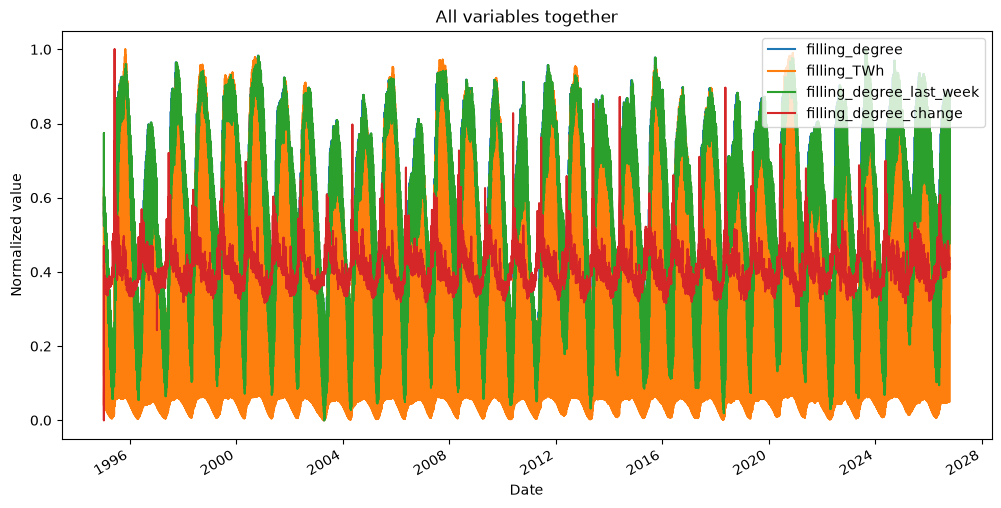

In [9]:
# Not all columns are relevant for plotting, so I select the ones I want to plot
columns_to_plot = [
    "filling_degree",
    "filling_TWh",
    "filling_degree_last_week",
    "filling_degree_change"
]

# Normalizing the data to make it easier to compare the different variables
normalized = reservoirs[columns_to_plot].copy()
normalized = (
    normalized - normalized.min()
) / (
    normalized.max() - normalized.min()
)

normalized.plot(
    figsize=(12, 6)
)

plt.title("All variables together")
plt.xlabel("Date")
plt.ylabel("Normalized value")
plt.legend()
plt.show()

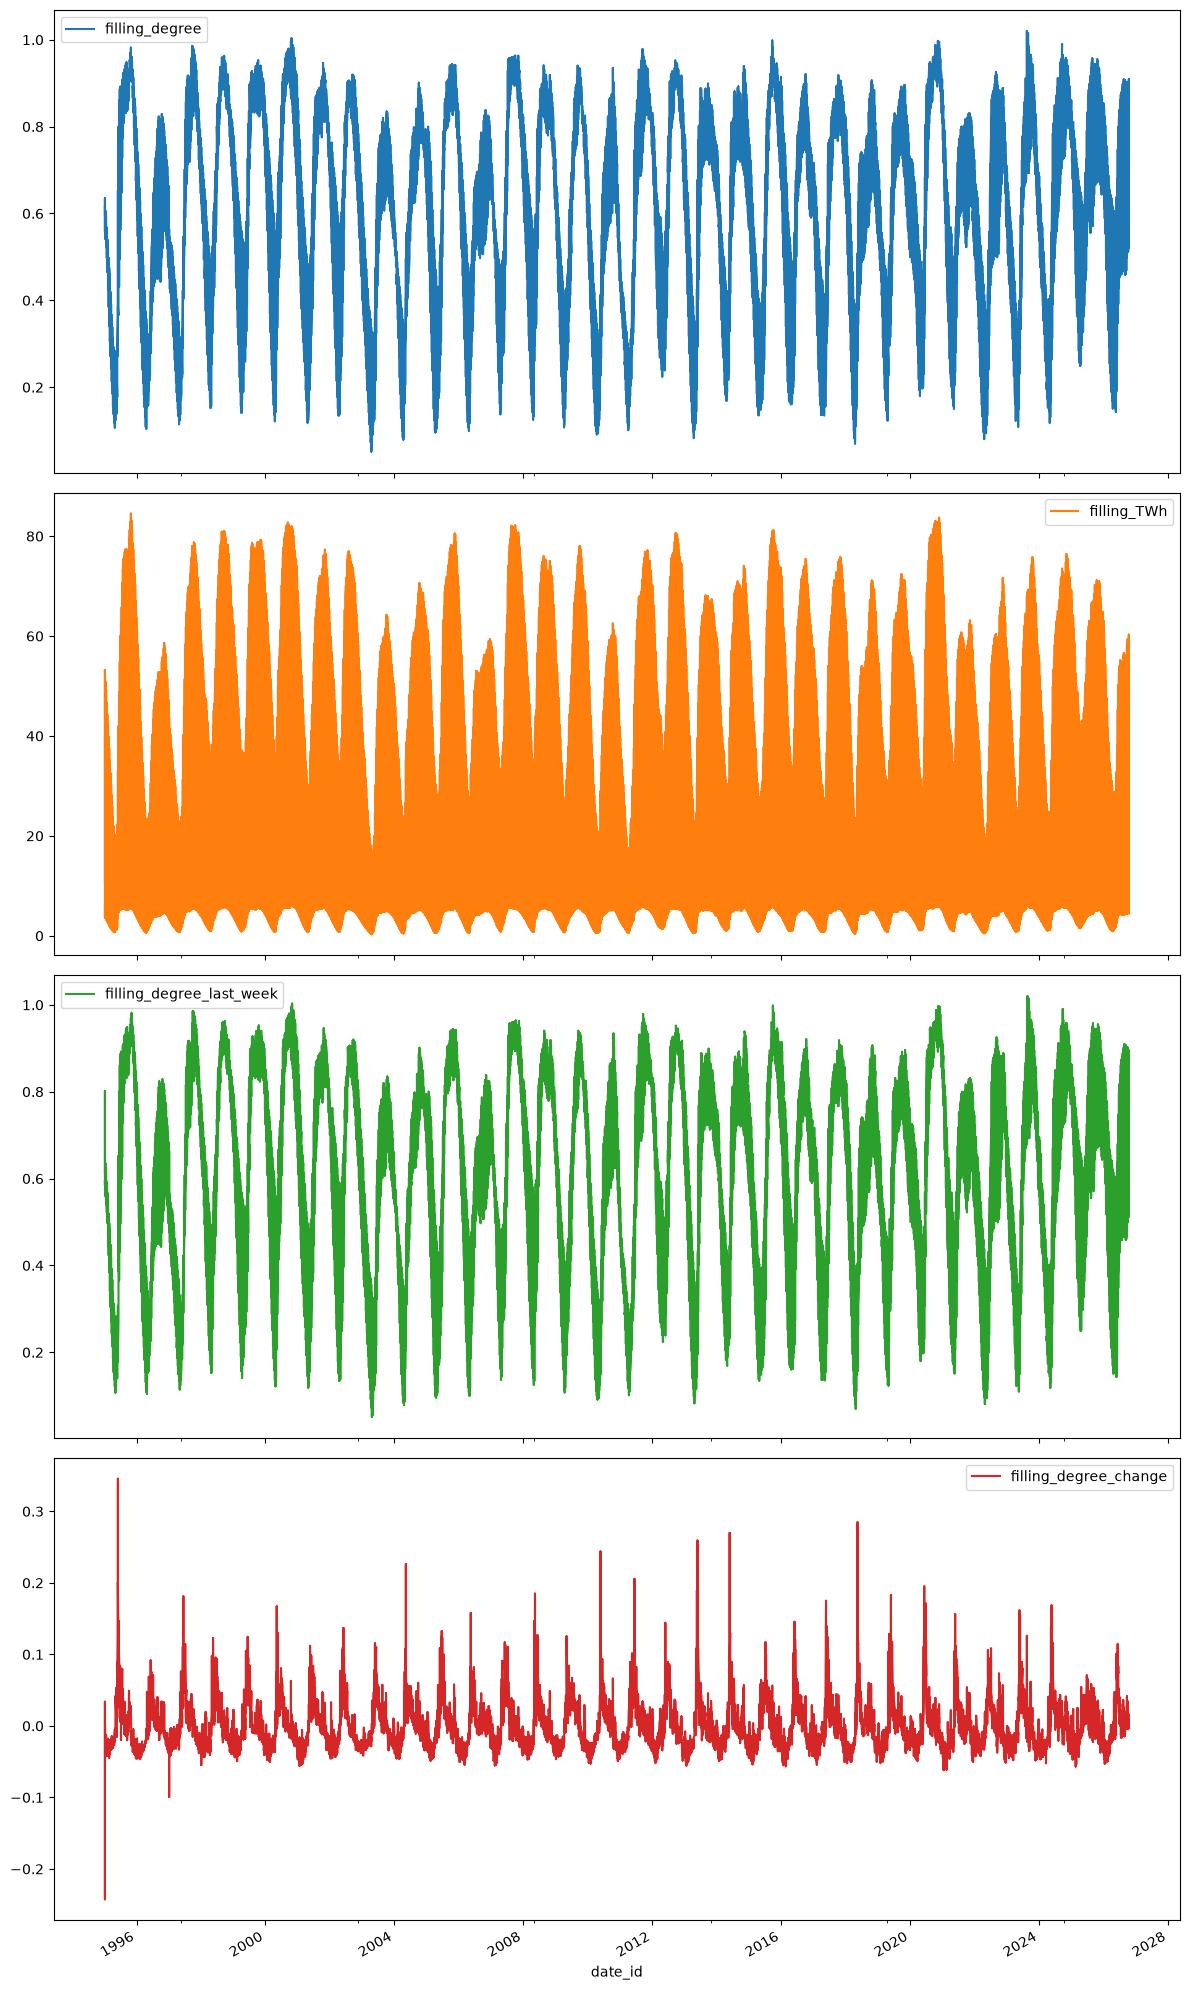

In [10]:
reservoirs[columns_to_plot].plot(
    subplots=True,
    figsize=(12, 20)
)

plt.tight_layout()
plt.show()

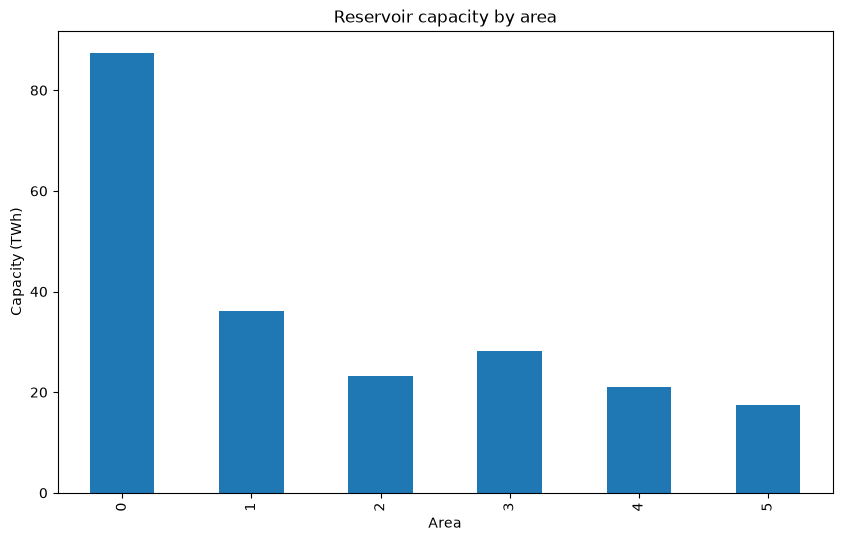

In [11]:
# Capacity by area, because capacity (not by area) is constant over time, we can just take the first value for each area
capacity = reservoirs.groupby("area_nr")["capacity_TWh"].first()
capacity.plot(
    kind="bar",
    figsize=(10, 6),
    title="Reservoir capacity by area",
    xlabel="Area",
    ylabel="Capacity (TWh)"
)

plt.show()

## Areas and time columns

**Areas.** The API covers three types of areas (`area_type` + `area_nr`):

| area_type | area_nr | Area |
|---|---|---|
| `NO` | 0 | All of Norway |
| `EL` | 1–5 | Electricity price areas NO1–NO5 (the same division ENTSO-E uses) |
| `VASS` | 1–3 | Watercourse areas: Sørøst-, Vest- and Midt-Norge. NVE's area list also has VASS 4 (Nord-Norge), but none of the data endpoints contain data for it |

`VASS` is a hydrological division and does not match the price areas.

**Time columns.** Lessons from part 1:
- Each date appears once per area. Using `date_id` as the index and plotting directly mixes all areas into one jagged line, so you have to filter on one area first.
- `date_id` is the Sunday that ends the ISO week, so the data is weekly, not daily.
- New data is published on Wednesdays at 13:00 (`next_publishing_date`).
- `filling_degree` is a fraction (0.72), not a percentage.
- The API has no date parameters. It always returns the full history.

In [12]:
# NVE's own list of areas, straight from the API
areas = nve.fetch_areas()
areas

,navn,navn_langt,beskrivelse,omrType,omrnr
0,Norge,Norge,Hele landet,NO,0
1,NO 1,Elspotområde 1,Sørøst-Norge. Omfatter østlige del av Østlande...,EL,1
2,NO 2,Elspotområde 2,Sørvest-Norge. Omfatter mesteparten av Vestfol...,EL,2
3,NO 3,Elspotområde 3,Midt-Norge. Omfatter nordre og vestlige del av...,EL,3
4,NO 4,Elspotområde 4,Nord-Norge. Omfatter resten av Trøndelag og No...,EL,4
5,NO 5,Elspotområde 5,Vest-Norge. Omfatter midtre del av Vestland op...,EL,5
6,VASS1,Vassdragsområde 1,"Sørøst-Norge. Østlandet, Agder og deler av Rog...",VASS,1
7,VASS2,Vassdragsområde 2,Vest-Norge. Resten av Rogaland og Vestland.,VASS,2
8,VASS3,Vassdragsområde 3,"Midt-Norge. Møre og Romsdal, Trøndelag og sørl...",VASS,3
9,VASS4,Vassdragsområde 4,Nord-Norge. Resten av Nordland og nordover.,VASS,4


In [17]:
# Checks which VASS areas appear in each of NVE's data endpoints.
for endpoint in ["HentOffentligData", "HentOffentligDataSisteUke", "HentOffentligDataMinMaxMedian"]:
    raw = pd.DataFrame(nve.fetch_json(endpoint))
    vass = raw[raw["omrType"] == "VASS"]
    vass_areas = sorted(int(nr) for nr in vass["omrnr"].unique())
    print(f"{endpoint}: VASS areas = {vass_areas}, rows = {len(vass)}")

HentOffentligData: VASS areas = [1, 2, 3], rows = 4974
HentOffentligDataSisteUke: VASS areas = [1, 2, 3], rows = 3
HentOffentligDataMinMaxMedian: VASS areas = [1, 2, 3], rows = 159


# API: ENTSO-E
- API reference: https://documenter.getpostman.com/view/7009892/2s93JtP3F6
- Transparency Platform: https://transparency.entsoe.eu/

In [16]:
from ind320 import entsoe

# Small test before fetching everything: one connection, one week
test_start = pd.Timestamp("2026-01-01", tz=entsoe.TIMEZONE)
test_end = pd.Timestamp("2026-01-08", tz=entsoe.TIMEZONE)

test_flows = entsoe.fetch_crossborder_flows(test_start, test_end, connections=[("NO_2", "DK_1")])
print(test_flows.shape)
test_flows.head()

Fetching NO_2 -> DK_1 ...
Fetching DK_1 -> NO_2 ...
(336, 6)


,time,connection,norwegian_area,foreign_area,direction,mwh
0,2025-12-31 23:00:00+00:00,NO_2-DK_1,NO_2,DK_1,out,0.0475
1,2026-01-01 00:00:00+00:00,NO_2-DK_1,NO_2,DK_1,out,0.0000
2,2026-01-01 01:00:00+00:00,NO_2-DK_1,NO_2,DK_1,out,0.0000
3,2026-01-01 02:00:00+00:00,NO_2-DK_1,NO_2,DK_1,out,0.0000
4,2026-01-01 03:00:00+00:00,NO_2-DK_1,NO_2,DK_1,out,0.0000


In [ ]:
# Sanity check 
# Checks that the test values look reasonable: one direction should usually be close to 0 while the other has values in the hundreds (physical flow mostly goes one way at a time)
test_flows.groupby("direction")["mwh"].describe()

,count,mean,std,min,25%,50%,75%,max
direction,,,,,,,,
in,168.0,313.364938,555.328414,0.0,0.000000,0.00000,329.957247,1605.295372
out,168.0,671.869613,638.502541,0.0,0.035625,559.40125,1395.263750,1629.375000


In [ ]:
# Fetches cross-border flows to and from Norway for the last two years, all 9 connections.
# 9 connections x 2 directions = 18 series. entsoe-py splits each into one request per year
# This took 25minutes on my run.
flows = entsoe.fetch_crossborder_flows()

print(flows.shape)
print("Period:", flows["time"].min(), "to", flows["time"].max())
flows.groupby(["connection", "direction"]).size()

Fetching NO_1 -> SE_3 ...
Fetching SE_3 -> NO_1 ...
Fetching NO_2 -> DE_LU ...
Fetching DE_LU -> NO_2 ...
Fetching NO_2 -> DK_1 ...
Fetching DK_1 -> NO_2 ...
Fetching NO_2 -> NL ...
Fetching NL -> NO_2 ...
Fetching NO_2 -> GB ...
Fetching GB -> NO_2 ...
Fetching NO_3 -> SE_2 ...
Fetching SE_2 -> NO_3 ...
Fetching NO_4 -> SE_2 ...
Fetching SE_2 -> NO_4 ...
Fetching NO_4 -> FI ...
Fetching FI -> NO_4 ...
Fetching NO_4 -> SE_1 ...
Fetching SE_1 -> NO_4 ...
(315360, 6)
Period: 2024-10-15 22:00:00+00:00 to 2026-10-15 21:00:00+00:00


connection  direction
NO_1-SE_3   in           17520
            out          17520
NO_2-DE_LU  in           17520
            out          17520
NO_2-DK_1   in           17520
            out          17520
NO_2-GB     in           17520
            out          17520
NO_2-NL     in           17520
            out          17520
NO_3-SE_2   in           17520
            out          17520
NO_4-FI     in           17520
            out          17520
NO_4-SE_1   in           17520
            out          17520
NO_4-SE_2   in           17520
            out          17520
dtype: int64

In [32]:
# Fetches cross-border flows for the last two years, all 9 connections (it took 25 minutes!)or loads the local backup if it exists. Delete the backup file to fetch fresh data
BACKUP_PATH = Path("../data/entsoe_flows.parquet")

if BACKUP_PATH.exists():
    flows = pd.read_parquet(BACKUP_PATH)
    print(f"Loaded backup from {BACKUP_PATH}")
else:
    flows = entsoe.fetch_crossborder_flows()
    flows.to_parquet(BACKUP_PATH)
    print(f"Fetched from ENTSO-E and saved backup to {BACKUP_PATH}")

print(flows.shape)
print("Period:", flows["time"].min(), "to", flows["time"].max())
flows.groupby(["connection", "direction"]).size()

Loaded backup from ..\data\entsoe_flows.parquet
(315360, 6)
Period: 2024-10-15 22:00:00+00:00 to 2026-10-15 21:00:00+00:00


connection  direction
NO_1-SE_3   in           17520
            out          17520
NO_2-DE_LU  in           17520
            out          17520
NO_2-DK_1   in           17520
            out          17520
NO_2-GB     in           17520
            out          17520
NO_2-NL     in           17520
            out          17520
NO_3-SE_2   in           17520
            out          17520
NO_4-FI     in           17520
            out          17520
NO_4-SE_1   in           17520
            out          17520
NO_4-SE_2   in           17520
            out          17520
dtype: int64

## Storing the data in Cassandra
The table is designed around how the data will be read. The pie chart shows one connection for one year, so the partition key is `(connection, year)`, and each partition holds exactly the data for one pie chart. Within a partition, the rows are sorted by `direction` and `time`.

`year` is the year in Norwegian time. `time` is stored in UTC.

In [33]:
# Table for the cross-border flows. Partition key (connection, year), sorted by direction and time
session.execute("""
    CREATE TABLE IF NOT EXISTS crossborder_flows (
        connection     text,
        year           int,
        direction      text,
        time           timestamp,
        norwegian_area text,
        foreign_area   text,
        mwh            double,
        PRIMARY KEY ((connection, year), direction, time)
    )
""")
print("Table ready")

Table ready


In [34]:
from pyspark.sql import functions as F

# Prepares the data for Cassandra:
# - year in Norwegian time (used in the partition key)
# - time sent to Spark as seconds since 1970-01-01 UTC (a plain number) and turned back into
#   a timestamp inside Spark, so it can't be shifted by the PC's local time on the way
# - text columns as plain Python objects, since Spark 3.5 can't read pandas' new string type
flows_to_store = flows.copy()
flows_to_store["year"] = flows_to_store["time"].dt.tz_convert(entsoe.TIMEZONE).dt.year
flows_to_store["time"] = (flows_to_store["time"] - pd.Timestamp("1970-01-01", tz="UTC")) // pd.Timedelta(seconds=1)

text_columns = ["connection", "norwegian_area", "foreign_area", "direction"]
flows_to_store[text_columns] = flows_to_store[text_columns].astype(object)

spark.conf.set("spark.sql.execution.arrow.pyspark.enabled", "false")   # Arrow fails on pandas' new string type

# Empties the table first, so rows from earlier runs are removed
session.execute("TRUNCATE crossborder_flows")

# Seconds since 1970 -> timestamp, done by Spark
flows_spark = spark.createDataFrame(flows_to_store).withColumn("time", F.col("time").cast("timestamp"))

flows_spark.write.format("org.apache.spark.sql.cassandra") \
    .options(keyspace=KEYSPACE, table="crossborder_flows") \
    .mode("append") \
    .save()

print(f"Wrote {flows_spark.count()} rows to Cassandra")

Wrote 315360 rows to Cassandra


In [35]:
# Reads the table back with Spark and counts rows per connection and year.
# Expected per connection: 3698 (2024), 17520 (2025), 13822 (2026)
stored = spark.read.format("org.apache.spark.sql.cassandra") \
    .options(keyspace=KEYSPACE, table="crossborder_flows") \
    .load()

stored.groupBy("connection", "year").count().orderBy("connection", "year").show(30)

# First and last hour should match what was fetched: 2024-10-15 22:00 and 2026-10-15 21:00 (UTC)
stored.agg(F.min("time"), F.max("time"), F.count("*")).show(truncate=False)

+----------+----+-----+
|connection|year|count|
+----------+----+-----+
| NO_1-SE_3|2024| 3698|
| NO_1-SE_3|2025|17520|
| NO_1-SE_3|2026|13822|
|NO_2-DE_LU|2024| 3698|
|NO_2-DE_LU|2025|17520|
|NO_2-DE_LU|2026|13822|
| NO_2-DK_1|2024| 3698|
| NO_2-DK_1|2025|17520|
| NO_2-DK_1|2026|13822|
|   NO_2-GB|2024| 3698|
|   NO_2-GB|2025|17520|
|   NO_2-GB|2026|13822|
|   NO_2-NL|2024| 3698|
|   NO_2-NL|2025|17520|
|   NO_2-NL|2026|13822|
| NO_3-SE_2|2024| 3698|
| NO_3-SE_2|2025|17520|
| NO_3-SE_2|2026|13822|
|   NO_4-FI|2024| 3698|
|   NO_4-FI|2025|17520|
|   NO_4-FI|2026|13822|
| NO_4-SE_1|2024| 3698|
| NO_4-SE_1|2025|17520|
| NO_4-SE_1|2026|13822|
| NO_4-SE_2|2024| 3698|
| NO_4-SE_2|2025|17520|
| NO_4-SE_2|2026|13822|
+----------+----+-----+

+-------------------+-------------------+--------+
|min(time)          |max(time)          |count(1)|
+-------------------+-------------------+--------+
|2024-10-15 22:00:00|2026-10-15 21:00:00|315360  |
+-------------------+-------------------+--------+


In [37]:
# Extracts the relevant columns from Cassandra with Spark:
# - month in Norwegian time, so "January" means January in Norway
# - time as seconds since 1970 (a plain number), converted in pandas below.
#   Like on the way in, this avoids the time passing through the PC's local time on the way out
extracted = (
    stored
    .withColumn("month", F.month(F.from_utc_timestamp("time", entsoe.TIMEZONE)))
    .select(
        "connection",
        "year",
        "month",
        "direction",
        F.col("time").cast("long").alias("time_seconds"),
        "mwh",
    )
)

extracted.printSchema()
extracted.show(5)

# Over to pandas for plotting, with the time converted back to UTC timestamps
flows_extracted = extracted.toPandas()
flows_extracted["time"] = pd.to_datetime(flows_extracted.pop("time_seconds"), unit="s", utc=True)
flows_extracted = flows_extracted.sort_values(["connection", "direction", "time"]).reset_index(drop=True)

print(flows_extracted.shape)
flows_extracted.head()

root
 |-- connection: string (nullable = false)
 |-- year: integer (nullable = false)
 |-- month: integer (nullable = true)
 |-- direction: string (nullable = true)
 |-- time_seconds: long (nullable = true)
 |-- mwh: double (nullable = true)

+----------+----+-----+---------+------------+--------+
|connection|year|month|direction|time_seconds|     mwh|
+----------+----+-----+---------+------------+--------+
| NO_4-SE_2|2024|   10|       in|  1729029600| 137.225|
| NO_4-SE_2|2024|   10|       in|  1729033200|  171.25|
| NO_4-SE_2|2024|   10|       in|  1729036800|  174.09|
| NO_4-SE_2|2024|   10|       in|  1729040400|165.8175|
| NO_4-SE_2|2024|   10|       in|  1729044000|  175.58|
+----------+----+-----+---------+------------+--------+
only showing top 5 rows

(315360, 6)


,connection,year,month,direction,mwh,time
0,NO_1-SE_3,2024,10,in,1002.5000,2024-10-15 22:00:00+00:00
1,NO_1-SE_3,2024,10,in,1167.9575,2024-10-15 23:00:00+00:00
2,NO_1-SE_3,2024,10,in,1428.6300,2024-10-16 00:00:00+00:00
3,NO_1-SE_3,2024,10,in,1440.4525,2024-10-16 01:00:00+00:00
4,NO_1-SE_3,2024,10,in,1586.7750,2024-10-16 02:00:00+00:00


## Plots
Both plots use the data extracted with Spark (`flows_extracted`). 2025 is used as the default year, since it is the only full year in the data (2024 and 2026 are partial).

In [38]:
# Choices for the plots. Change these to look at other connections or years
CHOSEN_CONNECTION = "NO_2-DK_1"
CHOSEN_YEAR = 2025

# Colours: one per direction, the same in both plots
DIRECTION_COLORS = {"out": "#2a78d6", "in": "#eb6834"}     # blue = out of Norway, orange = into Norway
DIRECTION_LABELS = {"out": "Out of Norway", "in": "Into Norway"}

print("Connections:", sorted(flows_extracted["connection"].unique()))

Connections: ['NO_1-SE_3', 'NO_2-DE_LU', 'NO_2-DK_1', 'NO_2-GB', 'NO_2-NL', 'NO_3-SE_2', 'NO_4-FI', 'NO_4-SE_1', 'NO_4-SE_2']


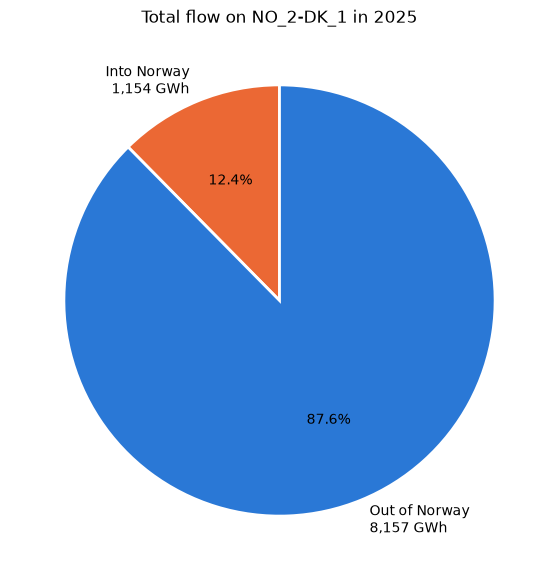

direction
in     1153.9
out    8157.3
Name: mwh, dtype: float64

In [39]:
# Pie chart: total amount in and out of Norway for one connection in one year
one_year = flows_extracted[
    (flows_extracted["connection"] == CHOSEN_CONNECTION)
    & (flows_extracted["year"] == CHOSEN_YEAR)
]

# Sum of MWh per direction, converted to GWh so the numbers are easier to read
totals_gwh = one_year.groupby("direction")["mwh"].sum() / 1000

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(
    totals_gwh.values,
    labels=[f"{DIRECTION_LABELS[d]}\n{gwh:,.0f} GWh" for d, gwh in totals_gwh.items()],
    colors=[DIRECTION_COLORS[d] for d in totals_gwh.index],
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
)
ax.set_title(f"Total flow on {CHOSEN_CONNECTION} in {CHOSEN_YEAR}")
plt.show()

totals_gwh.round(1)

In [ ]:
# Line plot: hourly flow in the first month (January) of the chosen year.
# One line per connection and direction. Add more connections to the list to compare them
CONNECTIONS_TO_PLOT = [CHOSEN_CONNECTION]

first_month = flows_extracted[
    (flows_extracted["connection"].isin(CONNECTIONS_TO_PLOT))
    & (flows_extracted["year"] == CHOSEN_YEAR)
    & (flows_extracted["month"] == 1)
]

fig, ax = plt.subplots(figsize=(14, 6))
for (connection, direction), group in first_month.groupby(["connection", "direction"]):
    # Plot in Norwegian time, so the hours match the month boundaries
    local_time = group["time"].dt.tz_convert(entsoe.TIMEZONE)
    color = DIRECTION_COLORS[direction] if len(CONNECTIONS_TO_PLOT) == 1 else None
    ax.plot(local_time, group["mwh"], label=f"{connection} {DIRECTION_LABELS[direction].lower()}",
            color=color, linewidth=1.2)

ax.set_title(f"Hourly flow, January {CHOSEN_YEAR}")
ax.set_xlabel("Date (Norwegian time)")
ax.set_ylabel("MWh per hour")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Storing the Spark-extracted data in MongoDB
The data is grouped with Spark into one document per connection, year, month and direction, with all the hours of that month as lists (`time` and `mwh`) and the month's total (`total_mwh`).
That gives about 450 documents instead of 315,000 rows, and matches how the Streamlit app reads the data: the pie chart sums `total_mwh` for one year, and the line plot uses the hours for the chosen months.

In [41]:
from datetime import datetime, timezone

# Groups the extracted data with Spark: one row per connection, year, month and direction,
# with the hours as a list sorted by time (sort_array sorts the structs by their first field, time_seconds)
monthly = (
    extracted
    .groupBy("connection", "year", "month", "direction")
    .agg(F.sort_array(F.collect_list(F.struct("time_seconds", "mwh"))).alias("hours"))
)

# Turns each Spark row into a MongoDB document.
# Time goes from seconds since 1970 to a UTC datetime here in Python (with time zone, so it can't be shifted)
documents = []
for row in monthly.collect():
    documents.append({
        "connection": row["connection"],
        "year": row["year"],
        "month": row["month"],
        "direction": row["direction"],
        "total_mwh": sum(hour["mwh"] for hour in row["hours"]),
        "time": [datetime.fromtimestamp(hour["time_seconds"], tz=timezone.utc) for hour in row["hours"]],
        "mwh": [hour["mwh"] for hour in row["hours"]],
    })

print(len(documents), "documents")

450 documents


In [42]:
# Writes the documents to MongoDB. The collection is emptied first, so running the cell again
# replaces the data instead of creating duplicates
flows_collection = mongo_db["crossborder_flows"]

flows_collection.delete_many({})
flows_collection.insert_many(documents)

# Index on the fields the Streamlit app filters on, so lookups are fast
flows_collection.create_index([("connection", 1), ("year", 1), ("month", 1)])

print(flows_collection.count_documents({}), "documents in MongoDB")

450 documents in MongoDB


In [43]:
# Checks that MongoDB gives the same totals as the pie chart above (computed from the Spark data in pandas)
from_mongo = flows_collection.aggregate([
    {"$match": {"connection": CHOSEN_CONNECTION, "year": CHOSEN_YEAR}},
    {"$group": {"_id": "$direction", "total_gwh": {"$sum": {"$divide": ["$total_mwh", 1000]}}}},
])

print("From MongoDB:", {doc["_id"]: round(doc["total_gwh"], 1) for doc in from_mongo})
print("Pie chart:   ", totals_gwh.round(1).to_dict())

From MongoDB: {'out': 8157.3, 'in': 1153.9}
Pie chart:    {'in': 1153.9, 'out': 8157.3}
